# Analyze per Die Matrix

This notebook demonstrates how to find the **reference behavior** for each die matrix, compare individual pieces against it, and identify which process segments show the most variability.

All analysis is performed on the gold parquet dataset (clean, validated pieces with partial times).

In [1]:
import pandas as pd
from pathlib import Path
                                                                                                                                                                                                               
GOLD_PATH = Path("../data/gold/pieces.parquet")
df = pd.read_parquet(GOLD_PATH)                                                                                                                                                                              
                                                                                                                                                                                                               
print(f"Loaded {len(df):,} pieces from gold")
print(f"Date range: {df['timestamp'].min().date()} → {df['timestamp'].max().date()}")                                                                                                                        
print(f"Die matrices: {sorted(df['die_matrix'].unique())}")


Loaded 167,300 pieces from gold
Date range: 2025-11-06 → 2026-03-11
Die matrices: [np.int64(4974), np.int64(5052), np.int64(5090), np.int64(5091)]


## 1. Reference profile per die matrix

The **reference (optimal) behavior** for each die matrix is defined by its median cumulative times. The median is more robust than the mean — it is not pulled by residual edge cases.

This table shows how long a typical piece takes to reach each stage, per matrix.

In [2]:
# Cumulative lifetime columns — the five stages of the physical process
cumulative_cols = [
    "lifetime_2nd_strike_s", "lifetime_3rd_strike_s", "lifetime_4th_strike_s",
    "lifetime_auxiliary_press_s", "lifetime_bath_s",
]

# Median per matrix: the "typical" piece's cumulative time at each stage.
# Median (not mean) is chosen because it is robust to residual edge cases
# that survived the cleaning — it answers "what does a normal piece look like?"
reference_cumulative = df.groupby("die_matrix")[cumulative_cols].median().round(1)
reference_cumulative

,lifetime_2nd_strike_s,lifetime_3rd_strike_s,lifetime_4th_strike_s,lifetime_auxiliary_press_s,lifetime_bath_s
die_matrix,,,,,
4974,17.3,23.9,37.1,54.2,55.9
5052,18.3,25.3,39.3,56.7,58.3
5090,17.7,24.6,38.5,56.5,58.1
5091,18.5,25.6,38.2,57.5,59.1


## 2. Reference partial times per die matrix

The partial times (time spent **between** consecutive stages) are more diagnostically useful than cumulative times — they isolate each segment of the process.

In [3]:
# Partial times — time spent BETWEEN consecutive stages (already computed in notebook 02)
partial_cols = [
    "partial_furnace_to_2nd_strike_s",
    "partial_2nd_to_3rd_strike_s",
    "partial_3rd_to_4th_strike_s",
    "partial_4th_strike_to_auxiliary_press_s",
    "partial_auxiliary_press_to_bath_s",
]

# Median per matrix: the "typical" time each segment takes.
# These are the reference values that every piece will be compared against
# in section 4 to detect which specific segment caused a delay.
reference_partials = df.groupby("die_matrix")[partial_cols].median().round(2)
reference_partials

,partial_furnace_to_2nd_strike_s,partial_2nd_to_3rd_strike_s,partial_3rd_to_4th_strike_s,partial_4th_strike_to_auxiliary_press_s,partial_auxiliary_press_to_bath_s
die_matrix,,,,,
4974,17.3,6.5,13.1,17.0,1.8
5052,18.3,6.9,13.7,17.3,1.6
5090,17.7,6.8,13.8,17.7,1.6
5091,18.5,7.0,13.5,17.0,1.6


## 3. Variability per segment per die matrix

Which segments are most variable? High standard deviation relative to the median (coefficient of variation) indicates segments where the process is less stable — these are the primary candidates for delay investigation.

**CV = std / median × 100%** — higher CV means more variability relative to the typical value.

In [4]:
# Coefficient of Variation (CV) = std / median × 100%
# CV normalizes variability against the typical value, so segments with
# different magnitudes can be compared fairly. A small absolute std on a
# short segment (e.g. 1.6s) can mean more instability than a larger std
# on a long segment (e.g. 17s). CV answers: "how jittery is this segment
# relative to its own normal?"
std_partials = df.groupby("die_matrix")[partial_cols].std()
median_partials = df.groupby("die_matrix")[partial_cols].median()

cv_partials = (std_partials / median_partials * 100).round(1)
print("Coefficient of Variation (%) per segment per matrix:")
cv_partials

Coefficient of Variation (%) per segment per matrix:


,partial_furnace_to_2nd_strike_s,partial_2nd_to_3rd_strike_s,partial_3rd_to_4th_strike_s,partial_4th_strike_to_auxiliary_press_s,partial_auxiliary_press_to_bath_s
die_matrix,,,,,
4974,9.2,4.4,2.4,7.0,2.7
5052,10.4,7.2,6.0,6.7,3.1
5090,13.6,10.8,8.1,9.1,5.4
5091,13.1,10.5,9.1,6.1,5.3


## 4. Deviation from reference per piece

For each piece, compute the deviation from its die matrix reference at each stage. Positive deviation = slower than reference. This allows identifying both slow individual pieces and systematic drifts.

In [5]:
# For each piece, compute how much each of its partial times deviates
# from the reference (median) for its own die matrix.
#
# Positive deviation = slower than the matrix's typical piece at that segment
# Negative deviation = faster than the matrix's typical piece at that segment
#
# Broadcasting strategy: merge the reference table into the main df so each
# piece row gets its matrix's reference values as additional columns, then
# subtract. This is vectorized and fast (no row-by-row apply).
ref_to_merge = reference_partials.add_suffix("_ref").reset_index()
df = df.merge(ref_to_merge, on="die_matrix", how="left")

deviation_cols = []
for col in partial_cols:
    dev_col = col.replace("partial_", "deviation_")
    df[dev_col] = df[col] - df[col + "_ref"]
    deviation_cols.append(dev_col)

# Drop the helper reference columns now that deviations are computed
df = df.drop(columns=[c + "_ref" for c in partial_cols])

# Show a sample of pieces with their deviations
print(f"Deviation columns added: {len(deviation_cols)}")
df[["die_matrix", "piece_id", "lifetime_bath_s"] + deviation_cols].head()

Deviation columns added: 5


,die_matrix,piece_id,lifetime_bath_s,deviation_furnace_to_2nd_strike_s,deviation_2nd_to_3rd_strike_s,deviation_3rd_to_4th_strike_s,deviation_4th_strike_to_auxiliary_press_s,deviation_auxiliary_press_to_bath_s
0,5052,251106001721,56.200001,-0.400000,-0.199999,-0.300000,-7.000015e-01,0.000002
1,5052,251106001722,56.400002,-0.400000,-0.199999,-0.399999,-4.000023e-01,0.000002
2,5052,251106001723,56.900002,-0.099999,-0.300002,-0.200000,-3.000000e-01,0.000002
3,5052,251106001724,57.099998,0.100000,-0.199999,-0.399999,-2.000015e-01,-0.000002
4,5052,251106001725,57.200001,-0.099999,-0.300002,-0.299998,-7.629395e-07,0.100001


## 5. Identify slow pieces and their penalized segment

A piece is considered **slow** if its total bath time exceeds the 90th percentile for its die matrix. For each slow piece, identify which segment contributed the most delay.

In [6]:
# A piece is "slow" if its total bath time exceeds the 90th percentile
# of its own die matrix — not a global cutoff. Using per-matrix p90 keeps
# the definition fair across matrices with different expected timings.
bath_p90_per_matrix = df.groupby("die_matrix")["lifetime_bath_s"].quantile(0.90)

# Broadcast the p90 threshold to each piece via mapping, then compare
df["bath_p90_ref"] = df["die_matrix"].map(bath_p90_per_matrix)
df["is_slow"] = df["lifetime_bath_s"] > df["bath_p90_ref"]

# For each slow piece, the "penalized segment" is the one with the
# highest positive deviation — i.e. the segment that contributed most
# to making the piece slow. idxmax returns the column name of the max.
df["penalized_segment"] = df[deviation_cols].idxmax(axis=1)
df.loc[~df["is_slow"], "penalized_segment"] = None  # only relevant for slow pieces

# Clean up helper column
df = df.drop(columns=["bath_p90_ref"])

n_slow = df["is_slow"].sum()
print(f"Slow pieces: {n_slow:,} of {len(df):,} ({n_slow/len(df)*100:.1f}%)")
print(f"\nBath p90 threshold per matrix (seconds):")
print(bath_p90_per_matrix.round(2).to_string())
print(f"\nSample of slow pieces with their penalized segment:")
df[df["is_slow"]][["die_matrix", "piece_id", "lifetime_bath_s", "penalized_segment"]].head(10)

Slow pieces: 16,369 of 167,300 (9.8%)

Bath p90 threshold per matrix (seconds):
die_matrix
4974    59.0
5052    61.8
5090    62.9
5091    63.4

Sample of slow pieces with their penalized segment:


,die_matrix,piece_id,lifetime_bath_s,penalized_segment
114,5052,251106001861,67.099998,deviation_4th_strike_to_auxiliary_press_s
225,5052,251106002034,63.700001,deviation_4th_strike_to_auxiliary_press_s
235,5052,251106002046,64.699997,deviation_4th_strike_to_auxiliary_press_s
935,5052,251106002864,67.099998,deviation_4th_strike_to_auxiliary_press_s
953,5052,251106002929,62.000000,deviation_2nd_to_3rd_strike_s
1065,5052,251106003159,62.599998,deviation_furnace_to_2nd_strike_s
1068,5052,251106003162,62.000000,deviation_furnace_to_2nd_strike_s
1070,5052,251106003164,62.299999,deviation_furnace_to_2nd_strike_s
1072,5052,251106003166,62.599998,deviation_furnace_to_2nd_strike_s
1073,5052,251106003167,62.200001,deviation_furnace_to_2nd_strike_s


## 6. Slow pieces per die matrix

How slow pieces distribute across die matrices, and which segments are most often penalized per matrix.

In [7]:
# Count of slow pieces per matrix and the most frequently penalized segment.
# Because "slow" is defined per-matrix (bath > p90 for that matrix), the
# slow count should be roughly 10% of each matrix's total by construction.
slow_summary = df[df["is_slow"]].groupby("die_matrix").agg(
    slow_count=("piece_id", "count"),
    most_common_penalized=("penalized_segment", lambda x: x.mode()[0]),
)
total_per_matrix = df.groupby("die_matrix").size()
slow_summary["total_pieces"] = total_per_matrix
slow_summary["slow_pct"] = (slow_summary["slow_count"] / total_per_matrix * 100).round(1)

print("Slow pieces summary per matrix:")
print(slow_summary)

# Detailed breakdown: how often each segment is the penalized one per matrix.
# This tells us WHERE delays most commonly originate for each matrix.
print("\nPenalized segment distribution per matrix (counts):")
penalized_dist = (
    df[df["is_slow"]]
    .groupby(["die_matrix", "penalized_segment"])
    .size()
    .unstack(fill_value=0)
)
penalized_dist

Slow pieces summary per matrix:
            slow_count              most_common_penalized  total_pieces  \
die_matrix                                                                
4974              1521  deviation_furnace_to_2nd_strike_s         15667   
5052              2033  deviation_furnace_to_2nd_strike_s         20798   
5090              7903  deviation_furnace_to_2nd_strike_s         81387   
5091              4912  deviation_furnace_to_2nd_strike_s         49448   

            slow_pct  
die_matrix            
4974             9.7  
5052             9.8  
5090             9.7  
5091             9.9  

Penalized segment distribution per matrix (counts):


penalized_segment,deviation_2nd_to_3rd_strike_s,deviation_3rd_to_4th_strike_s,deviation_4th_strike_to_auxiliary_press_s,deviation_auxiliary_press_to_bath_s,deviation_furnace_to_2nd_strike_s
die_matrix,,,,,
4974,4,18,177,0,1322
5052,27,139,191,0,1676
5090,333,1235,577,1,5757
5091,383,270,125,65,4069


## 7. Time evolution — detecting drift

Does the process get slower over time for a given matrix? Plot the daily median bath time per matrix to detect progressive deterioration.

Drift summary (last week vs first week median bath time):
 die_matrix  days_active  first_week_median_s  last_week_median_s  drift_s
       4974           11                 56.2                56.1     -0.1
       5052           14                 56.7                59.9      3.2
       5090           41                 56.1                60.0      3.9
       5091           22                 56.2                59.4      3.2


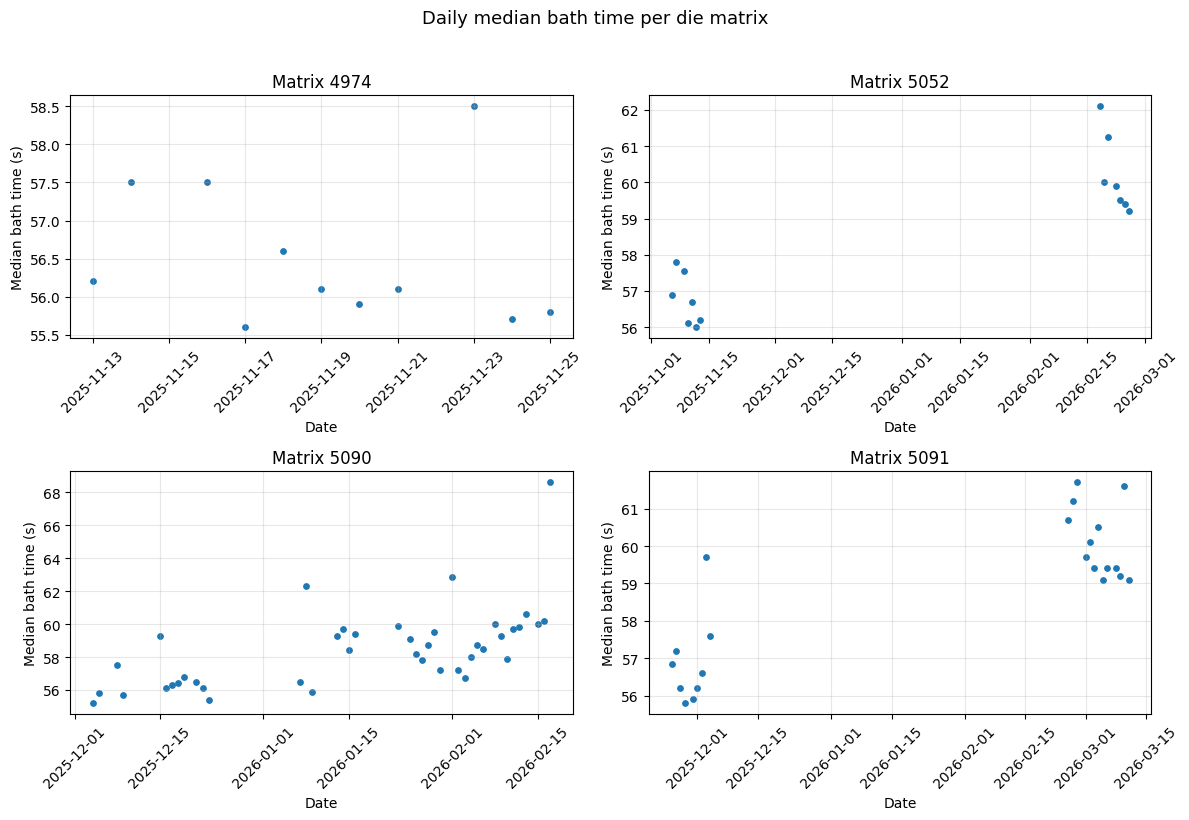

In [9]:
import matplotlib.pyplot as plt                                                                                                                                                                              
                                                                                                                                                                                                               
# Daily median bath time per matrix — the central question is whether a                                                                                                                                      
# given matrix's typical travel time progressively increases over its                                                                                                                                        
# active period, which would indicate tooling wear or process degradation.                                                                                                                                   
df["date"] = df["timestamp"].dt.date                                                                                                                                                                         
daily_median = (                                                                                                                                                                                             
    df.groupby(["die_matrix", "date"])["lifetime_bath_s"]                                                                                                                                                    
    .median()                                                                                                                                                                                                
    .reset_index()                                                                                   
)                                                                                                                                                                                                            
                                                                                                       
# Numerical drift summary: compare the median of the first 7 active days                                                                                                                                     
# against the median of the last 7 active days for each matrix.
# Note: for matrices with long inactive gaps (e.g. 5052, 5091 were reinstalled                                                                                                                               
# months apart), this compares two separate production campaigns rather than                                                                                                                                 
# continuous tooling wear — interpret accordingly.                                                                                                                                                           
drift_rows = []                                                                                                                                                                                              
for matrix in sorted(df["die_matrix"].unique()):                                                                                                                                                             
    m_data = daily_median[daily_median["die_matrix"] == matrix].sort_values("date")                  
    first = m_data.head(7)["lifetime_bath_s"].median()                                                                                                                                                       
    last = m_data.tail(7)["lifetime_bath_s"].median()                                                                                                                                                        
    drift_rows.append({                                                                                                                                                                                      
        "die_matrix": matrix,                                                                                                                                                                                
        "days_active": len(m_data),                                                                                                                                                                          
        "first_week_median_s": round(first, 2),
        "last_week_median_s": round(last, 2),                                                                                                                                                                
        "drift_s": round(last - first, 2),                                                                                                                                                                   
    })
drift_df = pd.DataFrame(drift_rows)                                                                                                                                                                          
print("Drift summary (last week vs first week median bath time):")                                   
print(drift_df.to_string(index=False))                                                                                                                                                                       
                                                                                                                                                                                                           
# Visualization: scatter-only so gaps between production campaigns are                                                                                                                                       
# visually honest — no connecting line faking a trend across months of                                                                                                                                       
# inactivity for matrices that were removed and later reinstalled.                                                                                                                                           
fig, axes = plt.subplots(2, 2, figsize=(12, 8))                                                                                                                                                              
for ax, matrix in zip(axes.flat, sorted(df["die_matrix"].unique())):                                                                                                                                         
  m_data = daily_median[daily_median["die_matrix"] == matrix]                                                                                                                                              
  ax.scatter(m_data["date"], m_data["lifetime_bath_s"], s=15)                                                                                                                                              
  ax.set_title(f"Matrix {matrix}")                                                                                                                                                                         
  ax.set_xlabel("Date")                                                                                                                                                                                    
  ax.set_ylabel("Median bath time (s)")                                                                                                                                                                    
  ax.tick_params(axis="x", rotation=45)                                                                                                                                                                    
  ax.grid(True, alpha=0.3)
                                                                                                                                                                                                           
plt.suptitle("Daily median bath time per die matrix", fontsize=13, y=1.02)                                                                                                                                   
plt.tight_layout()                                                                                                                                                                                           
plt.show()                                                                                                                                                                                                   
                                                                                                   
# Drop the helper date column                                                                                                                                                                                
df = df.drop(columns=["date"])

## 8. Segment variability ranking

Across all matrices, which process segment is the most unstable? This is where maintenance and process engineering should focus attention.

In [10]:
# Aggregate the per-matrix CVs into a single ranking across the whole line.
# Averaging CVs over matrices gives each segment a global "instability score".
# The segment at the top is the one process engineering should focus on first,
# because it is consistently the most unstable regardless of which die is in use.
avg_cv_per_segment = cv_partials.mean().sort_values(ascending=False).round(1)

print("Segment variability ranking (avg CV across matrices, higher = more unstable):")
print(avg_cv_per_segment.to_string())

Segment variability ranking (avg CV across matrices, higher = more unstable):
partial_furnace_to_2nd_strike_s            11.6
partial_2nd_to_3rd_strike_s                 8.2
partial_4th_strike_to_auxiliary_press_s     7.2
partial_3rd_to_4th_strike_s                 6.4
partial_auxiliary_press_to_bath_s           4.1


## 9. Summary

Key findings from the per-matrix analysis.

In [13]:
# Consolidated summary of the per-matrix analysis.
# Each section contributed one piece of the picture; this cell stitches
# them together so the key takeaways are visible at a glance.
print("=" * 70)
print("PER-MATRIX ANALYSIS — SUMMARY")
print("=" * 70)

print(f"\nTotal pieces analyzed: {len(df):,}")
print(f"Die matrices:          {sorted(df['die_matrix'].unique())}")

print("\n--- Reference median bath time per matrix ---")
print(df.groupby("die_matrix")["lifetime_bath_s"].median().round(2).to_string())

print("\n--- Most unstable segment per matrix (highest CV) ---")
most_unstable_per_matrix = cv_partials.idxmax(axis=1)
for matrix, seg in most_unstable_per_matrix.items():
    cv = cv_partials.loc[matrix, seg]
    print(f"  {matrix}: {seg}  (CV = {cv}%)")

print("\n--- Globally most unstable segment (avg CV across matrices) ---")
global_top = avg_cv_per_segment.index[0]
print(f"  {global_top}  (avg CV = {avg_cv_per_segment.iloc[0]}%)")

print("\n--- Slow pieces (bath > p90 for own matrix) ---")
print(f"  Total: {df['is_slow'].sum():,} ({df['is_slow'].mean()*100:.1f}%)")
print(f"\n  Most common penalized segment per matrix:")
for matrix in sorted(df["die_matrix"].unique()):
    slow_m = df[(df["die_matrix"] == matrix) & df["is_slow"]]
    if len(slow_m) > 0:
        top_seg = slow_m["penalized_segment"].mode()[0]
        print(f"    {matrix}: {top_seg}")

print("\n--- Drift over time (last week − first week median bath) ---")
for _, row in drift_df.iterrows():
    sign = "+" if row["drift_s"] >= 0 else ""
    print(f"  {row['die_matrix']}: {sign}{row['drift_s']}s  ({row['days_active']} active days)")

print("\n" + "=" * 70)

PER-MATRIX ANALYSIS — SUMMARY

Total pieces analyzed: 167,300
Die matrices:          [np.int64(4974), np.int64(5052), np.int64(5090), np.int64(5091)]

--- Reference median bath time per matrix ---
die_matrix
4974    55.9
5052    58.3
5090    58.1
5091    59.1

--- Most unstable segment per matrix (highest CV) ---
  4974: partial_furnace_to_2nd_strike_s  (CV = 9.2%)
  5052: partial_furnace_to_2nd_strike_s  (CV = 10.4%)
  5090: partial_furnace_to_2nd_strike_s  (CV = 13.6%)
  5091: partial_furnace_to_2nd_strike_s  (CV = 13.1%)

--- Globally most unstable segment (avg CV across matrices) ---
  partial_furnace_to_2nd_strike_s  (avg CV = 11.6%)

--- Slow pieces (bath > p90 for own matrix) ---
  Total: 16,369 (9.8%)

  Most common penalized segment per matrix:
    4974: deviation_furnace_to_2nd_strike_s
    5052: deviation_furnace_to_2nd_strike_s
    5090: deviation_furnace_to_2nd_strike_s
    5091: deviation_furnace_to_2nd_strike_s

--- Drift over time (last week − first week median bath) --